## 1-Setup Instructions

### 1.0 Import

Seting up RL dependecies for first time may be challenging. Some  torch or gymnasium (Sklearn lib in SL world!) environments need additional set up on your system. If you encountered error and failure after hours of search and try, feel free to be in contact with TA's.  Run the following commands to install dependencies before starting the notebook:

In [ ]:
!apt-get install -y xvfb python-opengl > /dev/null 2>&1
!apt-get install xvfb
!apt-get install x11-utils > /dev/null 2>&1

Better to use UV and Python 3.12  | https://docs.astral.sh/uv

In [ ]:
!pip install pyglet > /dev/null 2>&1
%pip install pyvirtualdisplay > /dev/null 2>&1
%pip install swig
%pip install stable-baselines3 "gymnasium[all]" pygame matplotlib numpy pandas gymnasium matplotlib


Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
  Using cached stable_baselines3-2.9.0-py3-none-any.whl.metadata (5.0 kB)
  Using cached pygame-2.6.1-cp314-cp314-linux_x86_64.whl
  Using cached pandas-3.0.5-cp314-cp314-manylinux_2_24_x86_64.manylinux_2_28_x86_64.whl.metadata (79 kB)
  Using cached torch-2.13.0-cp314-cp314-manylinux_2_28_x86_64.whl.metadata (38 kB)
  Using cached filelock-3.32.3-py3-none-any.whl.metadata (2.0 kB)
  Using cached setuptools-84.0.0-py3-none-any.whl.metadata (6.6 kB)
  Using cached sympy-1.14.0-py3-none-any.whl.metadata (12 kB)
  Using cached networkx-3.6.1-py3-none-any.whl.metadata (6.8 kB)
  Using cached jinja2-3.1.6-py3-none-any.whl.metadata (2.9 kB)
  Using cached fsspec-2026.7.0-py3-none-any.whl.metadata (10 kB)
  Using cached cuda_toolkit-13.0.3.0-py2.py3-none-any.whl.metadata (17 kB)
  Using cached cuda_bindings-13.3.1-cp314-cp314-manylinux_2_24_x86_64.manylinux_2_28_

Hamid is CE student who loves learning about RL. He tried to use **Gymnasium** and **Stable-Baselines3** to solve games he played as a kid.  

He started to list the games which was provided in gymnasium library.

### 1.1 MountainCar

In [3]:
from gymnasium import envs

all_envs = envs.registry
env_ids = [env_spec  for env_spec in all_envs]
print("Gymnasium envs listed:",sorted(env_ids))

Gymnasium envs listed: ['Acrobot-v1', 'Ant-v2', 'Ant-v3', 'Ant-v4', 'Ant-v5', 'BipedalWalker-v3', 'BipedalWalkerHardcore-v3', 'Blackjack-v1', 'CarRacing-v3', 'CartPole-v0', 'CartPole-v1', 'CliffWalking-v1', 'CliffWalkingSlippery-v1', 'FrozenLake-v1', 'FrozenLake8x8-v1', 'GymV21Environment-v0', 'GymV26Environment-v0', 'HalfCheetah-v2', 'HalfCheetah-v3', 'HalfCheetah-v4', 'HalfCheetah-v5', 'Hopper-v2', 'Hopper-v3', 'Hopper-v4', 'Hopper-v5', 'Humanoid-v2', 'Humanoid-v3', 'Humanoid-v4', 'Humanoid-v5', 'HumanoidStandup-v2', 'HumanoidStandup-v4', 'HumanoidStandup-v5', 'InvertedDoublePendulum-v2', 'InvertedDoublePendulum-v4', 'InvertedDoublePendulum-v5', 'InvertedPendulum-v2', 'InvertedPendulum-v4', 'InvertedPendulum-v5', 'LunarLander-v3', 'LunarLanderContinuous-v3', 'MountainCar-v0', 'MountainCarContinuous-v0', 'Pendulum-v1', 'Pusher-v2', 'Pusher-v4', 'Pusher-v5', 'Reacher-v2', 'Reacher-v4', 'Reacher-v5', 'Swimmer-v2', 'Swimmer-v3', 'Swimmer-v4', 'Swimmer-v5', 'Taxi-v4', 'Walker2d-v2', 'Walk

Then He selected Mountain Car Game to work with:

In [4]:
import gymnasium as gym
env = gym.make("MountainCar-v0", render_mode="rgb_array", goal_velocity=0.1)

print("Action Space {}".format(env.action_space))
print("State Space {}".format(env.observation_space))

print("Action Example: {}".format(env.action_space.sample()))
print("State Example: {}".format(env.observation_space.sample()))

Action Space Discrete(3)
State Space Box([-1.2  -0.07], [0.6  0.07], (2,), float32)
Action Example: 0
State Example: [-1.0649825  -0.06910152]


Hamid wanted to visualize the env for better understandig of gym envs. He had two options:


1.   rendering inside the colab
2.   rendering as video file



For ploting the game **inside** the colab he used **pyvirtualdisplay** package:

In [6]:
from pyvirtualdisplay import Display
import numpy as np
import matplotlib.pyplot as plt
from IPython import display as ipythondisplay

display = Display(visible=0, size=(400, 300))
display.start()

So He started modify the code to learn how action works and plot it. He selected action of

 *`2: Accelerate to the right`*

For every state of car.

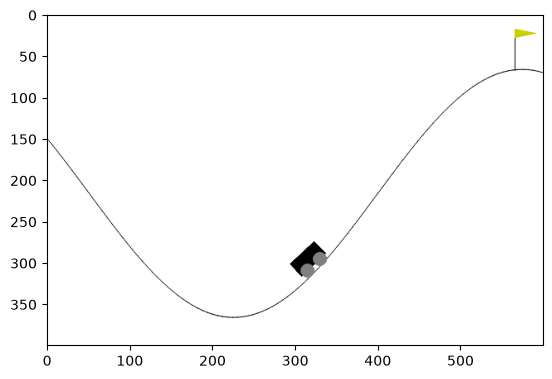

In [8]:
env.reset()
prev_screen = env.render( )
plt.imshow(prev_screen)

for i in range(40):
  # action = env.action_space.sample()  # Random action
  action = 2 # Action Hamid modified to practice
  obs, reward,terminated, truncated, info = env.step(action)
  screen = env.render()

  plt.imshow(screen)
  ipythondisplay.clear_output(wait=True)
  ipythondisplay.display(plt.gcf())

  if terminated:
    break

ipythondisplay.clear_output(wait=True)
env.close()

But for saving game as **video** he defined a function (it's okay if you don't understand just try to run the code and see the output, then try to modify envs!):

In [ ]:
import logging
from gymnasium.wrappers import RecordEpisodeStatistics, RecordVideo

training_period = 250  # record the agent's episode every 250
num_training_episodes = 1000  # total number of training episodes

env = gym.make("MountainCar-v0", render_mode="rgb_array")
env = RecordVideo(env, video_folder="MountainCar-v0-agent", name_prefix="training",
                  episode_trigger=lambda x: x % training_period == 0)
env = RecordEpisodeStatistics(env)

for episode_num in range(num_training_episodes):
    obs, info = env.reset()

    episode_over = False
    while not episode_over:
        action = env.action_space.sample()  # replace with actual agent
        obs, reward, terminated, truncated, info = env.step(action)

        episode_over = terminated or truncated

    logging.info(f"episode-{episode_num}", info["episode"])
env.close()

The videos are in MountainCar-v0-agent folder of your colab folder.

But the car couldn't reach the goal state on top of the right hill. So he tried to implement RL algorithm for learning it

In [ ]:
from stable_baselines3 import PPO
from stable_baselines3.common.env_util import make_vec_env

# Parallel environments can bet set but Hamid set 1 env
vec_env = make_vec_env("MountainCar-v0", n_envs=1)

model = PPO("MlpPolicy", vec_env, verbose=1)
model.learn(total_timesteps=25000)

del model # remove to demonstrate saving and loading


Using cuda device


/home/ali/devs/reinforcement-learning/intro/.venv/lib/python3.12/site-packages/stable_baselines3/common/on_policy_algorithm.py:150: UserWarning: You are trying to run PPO on the GPU, but it is primarily intended to run on the CPU when not using a CNN policy (you are using ActorCriticPolicy which should be a MlpPolicy). See https://github.com/DLR-RM/stable-baselines3/issues/1245 for more info. You can pass `device='cpu'` or `export CUDA_VISIBLE_DEVICES=` to force using the CPU.Note: The model will train, but the GPU utilization will be poor and the training might take longer than on CPU.
  warnings.warn(


---------------------------------
| rollout/           |          |
|    ep_len_mean     | 200      |
|    ep_rew_mean     | -200     |
| time/              |          |
|    fps             | 519      |
|    iterations      | 1        |
|    time_elapsed    | 3        |
|    total_timesteps | 2048     |
---------------------------------
-------------------------------------------
| rollout/                |               |
|    ep_len_mean          | 200           |
|    ep_rew_mean          | -200          |
| time/                   |               |
|    fps                  | 493           |
|    iterations           | 2             |
|    time_elapsed         | 8             |
|    total_timesteps      | 4096          |
| train/                  |               |
|    approx_kl            | 0.00023773071 |
|    clip_fraction        | 0             |
|    clip_range           | 0.2           |
|    entropy_loss         | -1.1          |
|    explained_variance   | -0.000731     |


**Loading saved model**

After training model using PPO and saving it, Hamid started to load the model with the name he saved in cell above:

In [14]:
model = PPO.load("ppo_MountainCar")

obs = vec_env.reset()
while True:
    action, _states = model.predict(obs)
    obs, rewards, dones, info = vec_env.step(action)
    print(obs, rewards, dones, info)
    if dones[0]:
      break

[[-0.566415   -0.00068486]] [-1.] [False] [{'TimeLimit.truncated': False}]
[[-5.6677967e-01 -3.6461547e-04]] [-1.] [False] [{'TimeLimit.truncated': False}]
[[-0.5678213  -0.00104166]] [-1.] [False] [{'TimeLimit.truncated': False}]
[[-0.5695323  -0.00171097]] [-1.] [False] [{'TimeLimit.truncated': False}]
[[-5.6989986e-01 -3.6755487e-04]] [-1.] [False] [{'TimeLimit.truncated': False}]
[[-0.56892127  0.00097859]] [-1.] [False] [{'TimeLimit.truncated': False}]
[[-5.686038e-01  3.174597e-04]] [-1.] [False] [{'TimeLimit.truncated': False}]
[[-0.56794983  0.00065397]] [-1.] [False] [{'TimeLimit.truncated': False}]
[[-0.5669642   0.00098562]] [-1.] [False] [{'TimeLimit.truncated': False}]
[[-0.56465423  0.00230995]] [-1.] [False] [{'TimeLimit.truncated': False}]
[[-0.56303716  0.00161709]] [-1.] [False] [{'TimeLimit.truncated': False}]
[[-0.56212497  0.00091219]] [-1.] [False] [{'TimeLimit.truncated': False}]
[[-0.5599245   0.00220049]] [-1.] [False] [{'TimeLimit.truncated': False}]
[[-0.5574

## 2-CartPole

Algorithm Comparison:
 RL algorithms and results (at least two algorithms e.g., PPO, DQN) based on:
- Total reward over time
- Hyperparameters (check the docs)

 [CartPole environment docs](https://gymnasium.farama.org/environments/classic_control/cart_pole/)

### 2.1 CartPole Solution: 

In [96]:
%load_ext tensorboard

The tensorboard extension is already loaded. To reload it, use:
  %reload_ext tensorboard


In [12]:
# Import CartPole env 
from stable_baselines3 import A2C , PPO , DQN
import gymnasium as gym
from gymnasium import spaces
import numpy as np

# For fix tensorboard error
from torch.utils.tensorboard import SummaryWriter
from stable_baselines3.common import utils, logger

utils.SummaryWriter = SummaryWriter
logger.SummaryWriter = SummaryWriter


In [100]:
# A2C algorithm
env = gym.make("CartPole-v1")
model = A2C("MlpPolicy", env, verbose=1, tensorboard_log="./CP/A2C_CartPole_tensorboard/")
model.learn(total_timesteps=250_000)

Using cuda device
Wrapping the env with a `Monitor` wrapper
Wrapping the env in a DummyVecEnv.
Logging to ./CP/A2C_CartPole_tensorboard/A2C_1


/home/ali/devs/reinforcement-learning/intro/.venv/lib/python3.12/site-packages/stable_baselines3/common/on_policy_algorithm.py:150: UserWarning: You are trying to run A2C on the GPU, but it is primarily intended to run on the CPU when not using a CNN policy (you are using ActorCriticPolicy which should be a MlpPolicy). See https://github.com/DLR-RM/stable-baselines3/issues/1245 for more info. You can pass `device='cpu'` or `export CUDA_VISIBLE_DEVICES=` to force using the CPU.Note: The model will train, but the GPU utilization will be poor and the training might take longer than on CPU.
  warnings.warn(


------------------------------------
| rollout/              |          |
|    ep_len_mean        | 20.9     |
|    ep_rew_mean        | 20.9     |
| time/                 |          |
|    fps                | 404      |
|    iterations         | 100      |
|    time_elapsed       | 1        |
|    total_timesteps    | 500      |
| train/                |          |
|    entropy_loss       | -0.69    |
|    explained_variance | -0.155   |
|    learning_rate      | 0.0007   |
|    n_updates          | 99       |
|    policy_loss        | 1.94     |
|    value_loss         | 9.46     |
------------------------------------
------------------------------------
| rollout/              |          |
|    ep_len_mean        | 23.3     |
|    ep_rew_mean        | 23.3     |
| time/                 |          |
|    fps                | 385      |
|    iterations         | 200      |
|    time_elapsed       | 2        |
|    total_timesteps    | 1000     |
| train/                |          |
|

In [101]:
# DQN algorithm
env = gym.make("CartPole-v1")
model = DQN("MlpPolicy", env, verbose=1, tensorboard_log="./CP/DQN_CartPole_tensorboard/")
model.learn(total_timesteps=250_000)

Using cuda device
Wrapping the env with a `Monitor` wrapper
Wrapping the env in a DummyVecEnv.
Logging to ./CP/DQN_CartPole_tensorboard/DQN_1
----------------------------------
| rollout/            |          |
|    ep_len_mean      | 17       |
|    ep_rew_mean      | 17       |
|    exploration_rate | 0.997    |
| time/               |          |
|    episodes         | 4        |
|    fps              | 7536     |
|    time_elapsed     | 0        |
|    total_timesteps  | 68       |
----------------------------------
----------------------------------
| rollout/            |          |
|    ep_len_mean      | 29.6     |
|    ep_rew_mean      | 29.6     |
|    exploration_rate | 0.991    |
| time/               |          |
|    episodes         | 8        |
|    fps              | 1921     |
|    time_elapsed     | 0        |
|    total_timesteps  | 237      |
| train/              |          |
|    learning_rate    | 0.0001   |
|    loss             | 0.488    |
|    n_updates    

In [102]:
#  PPO algorithm
env = gym.make("CartPole-v1")
model = PPO("MlpPolicy", env, verbose=1, tensorboard_log="./CP/PPO_CartPole_tensorboard/")
model.learn(total_timesteps=250_000)

Using cuda device
Wrapping the env with a `Monitor` wrapper
Wrapping the env in a DummyVecEnv.
Logging to ./CP/PPO_CartPole_tensorboard/PPO_1


/home/ali/devs/reinforcement-learning/intro/.venv/lib/python3.12/site-packages/stable_baselines3/common/on_policy_algorithm.py:150: UserWarning: You are trying to run PPO on the GPU, but it is primarily intended to run on the CPU when not using a CNN policy (you are using ActorCriticPolicy which should be a MlpPolicy). See https://github.com/DLR-RM/stable-baselines3/issues/1245 for more info. You can pass `device='cpu'` or `export CUDA_VISIBLE_DEVICES=` to force using the CPU.Note: The model will train, but the GPU utilization will be poor and the training might take longer than on CPU.
  warnings.warn(


---------------------------------
| rollout/           |          |
|    ep_len_mean     | 23.3     |
|    ep_rew_mean     | 23.3     |
| time/              |          |
|    fps             | 731      |
|    iterations      | 1        |
|    time_elapsed    | 2        |
|    total_timesteps | 2048     |
---------------------------------
-----------------------------------------
| rollout/                |             |
|    ep_len_mean          | 28.6        |
|    ep_rew_mean          | 28.6        |
| time/                   |             |
|    fps                  | 586         |
|    iterations           | 2           |
|    time_elapsed         | 6           |
|    total_timesteps      | 4096        |
| train/                  |             |
|    approx_kl            | 0.009087042 |
|    clip_fraction        | 0.119       |
|    clip_range           | 0.2         |
|    entropy_loss         | -0.686      |
|    explained_variance   | -0.00171    |
|    learning_rate        | 0.

In [103]:
# modify hyperparameters
learning_rates = [0.0001, 0.01]  
gammas = [0.95, 0.99]

In [104]:
# A2C algorithm - hyperparameters
for lr in learning_rates:
    for gamma in gammas:
        model = A2C("MlpPolicy", env, verbose=0, learning_rate=lr,  gamma=gamma, tensorboard_log=f'./CP/A2C_CartPole_tensorboard/a2c_lr{lr}_gamma{gamma}')
        model.learn(total_timesteps=250_000)

/home/ali/devs/reinforcement-learning/intro/.venv/lib/python3.12/site-packages/stable_baselines3/common/on_policy_algorithm.py:150: UserWarning: You are trying to run A2C on the GPU, but it is primarily intended to run on the CPU when not using a CNN policy (you are using ActorCriticPolicy which should be a MlpPolicy). See https://github.com/DLR-RM/stable-baselines3/issues/1245 for more info. You can pass `device='cpu'` or `export CUDA_VISIBLE_DEVICES=` to force using the CPU.Note: The model will train, but the GPU utilization will be poor and the training might take longer than on CPU.
  warnings.warn(


In [105]:
# DQN algorithm - hyperparameters
for lr in learning_rates:
    for gamma in gammas:
        model = DQN("MlpPolicy", env, verbose=0, learning_rate=lr,  gamma=gamma, tensorboard_log=f'./CP/DQN_CartPole_tensorboard/dqn_lr{lr}_gamma{gamma}')
        model.learn(total_timesteps=250_000)

In [106]:
# PPO algorithm - hyperparameters
for lr in learning_rates:
    for gamma in gammas:
        model = PPO("MlpPolicy", env, verbose=0, learning_rate=lr,  gamma=gamma, tensorboard_log=f'./CP/PPO_CartPole_tensorboard/ppo_lr{lr}_gamma{gamma}')
        model.learn(total_timesteps=250_000)

In [107]:
from gymnasium import  RewardWrapper

class DoubledReward(RewardWrapper):
    def reward(self, reward):
        return reward * 2

wrapped_env = DoubledReward(env)

In [108]:
# A2C algorithm - reward
model = A2C("MlpPolicy", wrapped_env, verbose=0, tensorboard_log="./CP/A2C_CartPole_tensorboard/reward_wrapped_env_a2c")
model.learn(total_timesteps=250_000)

In [109]:
# DQN algorithm - reward
model = DQN("MlpPolicy", wrapped_env, verbose=0, tensorboard_log="./CP/DQN_CartPole_tensorboard/reward_wrapped_env_dqn")
model.learn(total_timesteps=250_000)

In [110]:
# PPO algorithm - reward
model = PPO("MlpPolicy", wrapped_env, verbose=0, tensorboard_log="./CP/PPO_CartPole_tensorboard/reward_wrapped_env_ppo")
model.learn(total_timesteps=250_000)

In [63]:
!tensorboard --logdir ./CP

I0000 00:00:1787139852.152280   98854 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1787139852.197409   98854 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1787139853.612722   98854 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
E0000 00:00:1787139854.524590   98854 cuda_executor.cc:1737] INTERNAL: CUDA Runtime error: Failed call to cudaGetRuntimeVersion: Error loading CUDA libraries. GPU will not be used.: Error loading CUDA libraries. GPU will not be used.
W0000 00:00:1787139854.544107   98854 gpu_device.cc:2365] Cannot dlopen some GPU libraries. Please make sure the missing libraries mentioned above are installed properly if you would like to use GPU. Follow the guide at htt

## 3-FrozenLake Env

In [111]:
from stable_baselines3 import A2C , PPO , DQN
import gymnasium as gym
from gymnasium import spaces
import numpy as np

In [ ]:
# A2C algorithm
env = gym.make("FrozenLake-v1" , is_slippery=True)
model = A2C("MlpPolicy" ,env , verbose=0, tensorboard_log="./FL/A2C_FrozenLake_tensorboard/")
model.learn(total_timesteps=250_000)

In [ ]:
# DQN algorithm
env = gym.make("FrozenLake-v1" , is_slippery=True)
model = DQN("MlpPolicy" ,env , verbose=0, tensorboard_log="./FL/DQN_FrozenLake_tensorboard/")
model.learn(total_timesteps=250_000)

In [ ]:
# PPO algorithm
env = gym.make("FrozenLake-v1" , is_slippery=True)
model = PPO("MlpPolicy" ,env , verbose=0, tensorboard_log="./FL/PPO_FrozenLake_tensorboard/")
model.learn(total_timesteps=250_000)

In [ ]:
# modify hyperparameters
learning_rates = [0.0001, 0.01]  
gammas = [0.95, 0.99]

In [115]:
# A2C algorithm - hyperparameters
for lr in learning_rates:
    for gamma in gammas:
        model = A2C("MlpPolicy", env, verbose=0, learning_rate=lr,  gamma=gamma, tensorboard_log=f'./FL/A2C_FrozenLake_tensorboard/a2c_lr{lr}_gamma{gamma}')
        model.learn(total_timesteps=250_000)

In [116]:
# PPO algorithm - hyperparameters
for lr in learning_rates:
    for gamma in gammas:
        model = PPO("MlpPolicy", env, verbose=0, learning_rate=lr,  gamma=gamma, tensorboard_log=f'./FL/PPO_FrozenLake_tensorboard/ppo_lr{lr}_gamma{gamma}')
        model.learn(total_timesteps=250_000)

In [117]:
# DQN algorithm - hyperparameters
for lr in learning_rates:
    for gamma in gammas:
        model = DQN("MlpPolicy", env, verbose=0, learning_rate=lr,  gamma=gamma, tensorboard_log=f'./FL/DQN_FrozenLake_tensorboard/dqn_lr{lr}_gamma{gamma}')
        model.learn(total_timesteps=250_000)

In [118]:
from gymnasium import  RewardWrapper
class DoubledReward(RewardWrapper):
    def reward(self, reward):
        return reward * 2

wrapped_env = DoubledReward(env)


In [119]:
model = A2C("MlpPolicy", wrapped_env, verbose=0, tensorboard_log="./FL/A2C_FrozenLake_tensorboard/reward_wrapped_env_a2c")
model.learn(total_timesteps=250_000)

In [120]:
model = PPO("MlpPolicy", wrapped_env, verbose=0, tensorboard_log="./FL/PPO_FrozenLake_tensorboard/reward_wrapped_env_ppo")
model.learn(total_timesteps=250_000)

In [121]:
model = DQN("MlpPolicy", wrapped_env, verbose=0, tensorboard_log="./FL/DQN_FrozenLake_tensorboard/reward_wrapped_env_dqn")
model.learn(total_timesteps=250_000)

In [ ]:
!tensorboard --logdir ./FL

## 4-Creating Custom Environment

In this question, you were required to model **a custom 4*4 gridworld problem** as Markov Decision Processes (MDPs). 



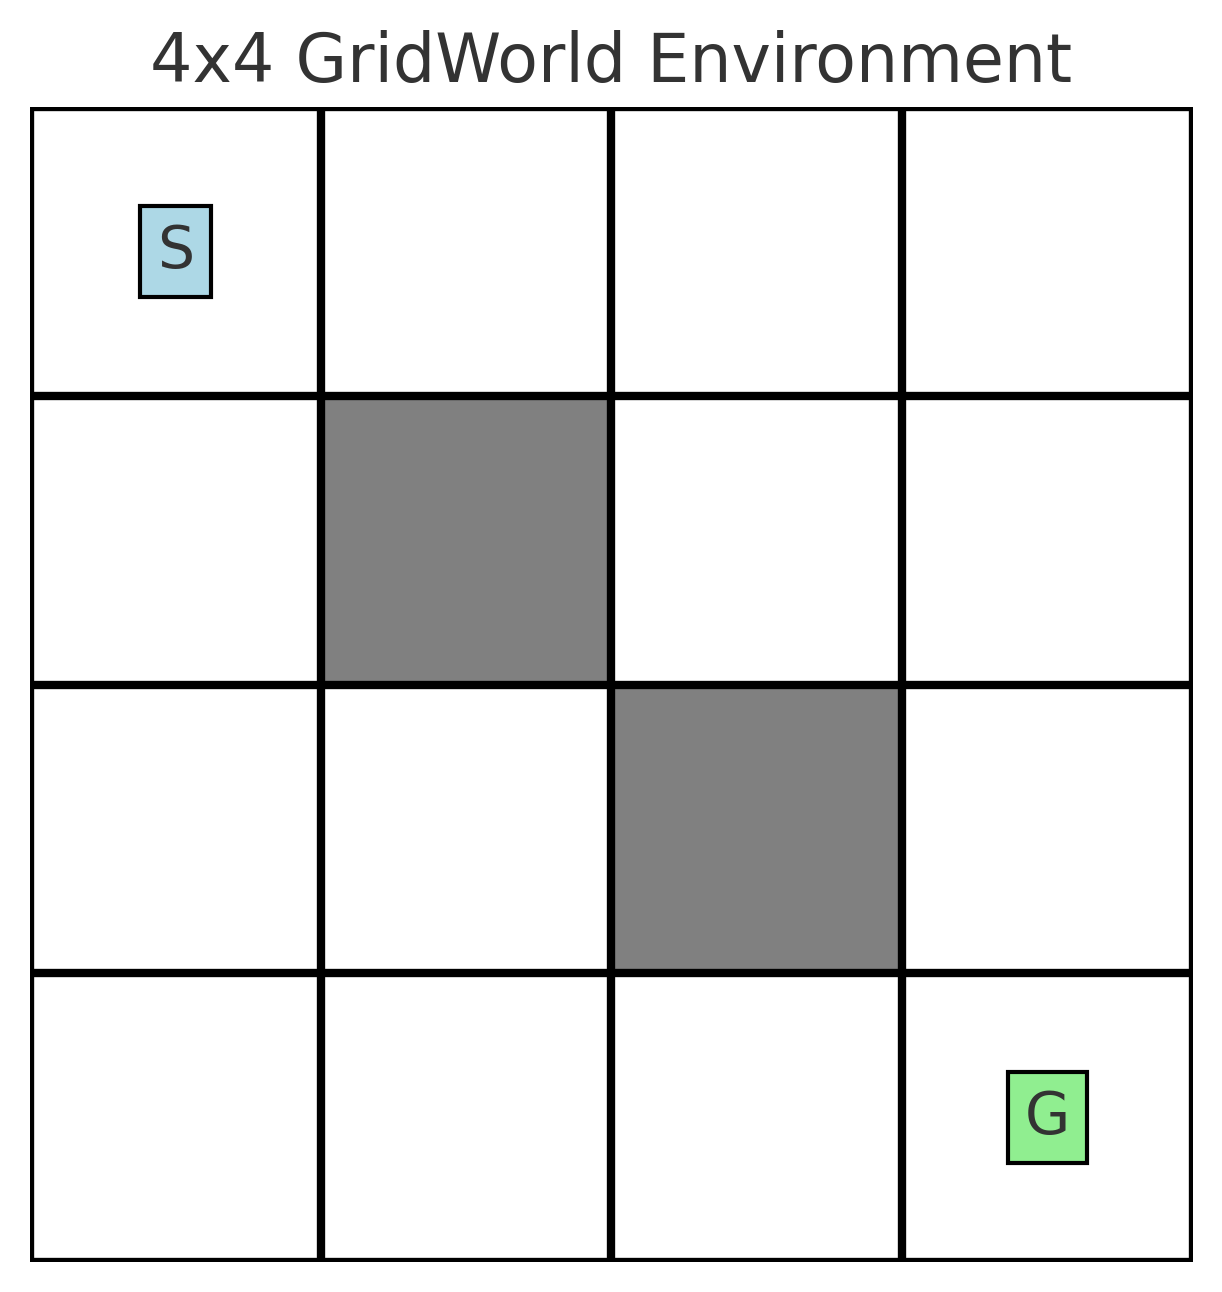

- **State Space ($ S $)**: The set of all possible states the agent can be in.
- **Action Space ($ A $)**: The set of all possible actions the agent can take.
- **Reward Function ($ R $)**: The reward the agent receives for taking an action in a given state.
- **Transition Probability ($ P $)**: The probability of transitioning to a new state given the current state and action. If the environment is deterministic, this can be omitted.

After defining the MDP components, implement problem using the **Gymnasium standard API**. Then, test the environments using various reinforcement learning algorithms (e.g., Q-Learning, DQN, PPO) and evaluate their performance.

In [7]:
class GWEnv(gym.Env):

    def __init__(self, grid_size=4):
        super().__init__()
        self.grid_size = grid_size
        self.start = (0, 0)
        self.goal = (grid_size - 1, grid_size - 1)
        self.holes = {(1, 1), (2, 2)}

        self.action_space = spaces.Discrete(4)
        self.observation_space = spaces.Discrete(grid_size ** 2)

        self.moves = (
            (-1, 0),  # Up
            (1, 0),   # Down
            (0, -1),  # Left
            (0, 1),   # Right
        )

        self.state = self.start

    def get_obs(self):
        row, col = self.state
        return row * self.grid_size + col

    def step(self, action):
        row, col = self.state
        d_row, d_col = self.moves[action]
        next_row = max(0, min(row + d_row, self.grid_size - 1))
        next_col = max(0, min(col + d_col, self.grid_size - 1))
        next_state = (next_row, next_col)

        if next_state in self.holes:
            reward = -1
            terminated = True
        elif next_state == self.goal:
            reward = 10
            terminated = True
        else:
            reward = 0
            terminated = False

        self.state = next_state
        return self.get_obs(), reward, terminated, False, {}

    def reset(self, *, seed=None, options=None):
        super().reset(seed=seed)
        self.state = self.start
        return self.get_obs(), {}

    def render(self):
        grid = [["." for _ in range(self.grid_size)] for _ in range(self.grid_size)]

        sr, sc = self.start
        gr, gc = self.goal
        grid[sr][sc] = "S"
        grid[gr][gc] = "G"

        for r, c in self.holes:
            grid[r][c] = "H"

        rr, cc = self.state
        grid[rr][cc] = "A"

        for row in grid:
            print("  ".join(row))
        print()

In [8]:
def qlearning_gw(env,learning_rate=0.1,discount_factor=0.99,episodes=5000,max_steps_per_episode=100,):
    writer = SummaryWriter(f"GW/Qlearning_GridWorld/"f"experiment_lr_{learning_rate}_{discount_factor}")

    num_states = env.observation_space.n
    num_actions = env.action_space.n

    q_values = np.zeros((num_states, num_actions))
    alpha = learning_rate
    gamma = discount_factor

    epsilon = 1.0
    decay = 0.005

    episode_rewards = [ ]

    for episode in range(episodes):

        state, _ = env.reset()
        total_reward = 0

        for _ in range(max_steps_per_episode):

            # Epsilon-greedy action selection
            if random.random() < epsilon:
                action = env.action_space.sample()
            else:
                action = np.argmax(q_values[state])

            next_state, reward, terminated, truncated, _ = env.step(action)

            # Q-Learning target
            if terminated or truncated:
                target = reward
            else:
                target = reward + gamma * np.max(q_values[next_state])

            # Update Q-value
            q_values[state, action] += alpha * (
                target - q_values[state, action]
            )

            state = next_state
            total_reward += reward

            if terminated or truncated:
                break

        # Epsilon decay
        epsilon = 1 / (1 + decay * episode)
        episode_rewards.append(total_reward)
        avg_reward = np.mean(episode_rewards[-100:])

        writer.add_scalar("Mean_Episode_Reward",avg_reward,episode)

    writer.close()
    env.close()

    return q_values

In [9]:
def simulate_gw(environment=None, q_matrix=None, max_steps_per_run=100, step_delay=0.5):
    if environment is None:
        environment = GWEnv()
    if q_matrix is None:
        raise ValueError("q_matrix is required.")

    state, _ = environment.reset()
    print("Starting state:", state)
    environment.render()
    sleep(step_delay)

    for step in range(max_steps_per_run):
        action = int(np.argmax(q_matrix[state]))
        next_state, reward, terminated, truncated, _ = environment.step(action)
        state = next_state

        environment.render()
        sleep(step_delay)

        if terminated or truncated:
            print(f"Run completed in {step + 1} steps. Reward: {reward}")
            break
    else:
        print(f"Maximum steps ({max_steps_per_run}) reached.")

In [15]:
import random
import time

env = GWEnv()
q_values = qlearning_gw(env = env , learning_rate = 0.9 , discount_factor = .99 )

In [16]:
from time import sleep

simulate_gw(environment = env, q_matrix = q_values , max_steps_per_run= 500)

Starting state: 0
A  .  .  .
.  H  .  .
.  .  H  .
.  .  .  G

S  .  .  .
A  H  .  .
.  .  H  .
.  .  .  G

S  .  .  .
.  H  .  .
A  .  H  .
.  .  .  G

S  .  .  .
.  H  .  .
.  .  H  .
A  .  .  G

S  .  .  .
.  H  .  .
.  .  H  .
.  A  .  G

S  .  .  .
.  H  .  .
.  .  H  .
.  .  A  G

S  .  .  .
.  H  .  .
.  .  H  .
.  .  .  A

Run completed in 6 steps. Reward: 10


In [17]:
learning_rates = [0.1, 0.5, 0.7, 0.9]  
gammas = [0.90, 0.95, 0.99]

for lr in learning_rates:
    for gamma in gammas:
        qlearning_gw(env = env , learning_rate = lr , discount_factor = gamma )

In [18]:
!tensorboard --logdir ./GW

I0000 00:00:1787300155.681199  181950 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1787300155.719315  181950 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1787300156.727006  181950 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
E0000 00:00:1787300157.497063  181950 cuda_executor.cc:1737] INTERNAL: CUDA Runtime error: Failed call to cudaGetRuntimeVersion: Error loading CUDA libraries. GPU will not be used.: Error loading CUDA libraries. GPU will not be used.
W0000 00:00:1787300157.515938  181950 gpu_device.cc:2365] Cannot dlopen some GPU libraries. Please make sure the missing libraries mentioned above are installed properly if you would like to use GPU. Follow the guide at htt

## 5-Credits


### [Deep Reinforcement Learning course](https://deeprlcourse.github.io/homeworks)
Dr. Mohammad Hossein Rohban